# 4 — Prompt, batching, and order sensitivity

A contemporaneous comparison of the **original reference prompt** and a
training-anchored, five-example prompt. Both use the same five output strings,
JSON schema, original six hosted endpoints, and provider-specific settings.
No historical labels are substituted for new reference-prompt calls.

The frozen design selects 1,000 unique descriptions uniformly without replacement
from all 4,690 descriptions (seed 20261104). Every model/prompt is run three times
on the same 50 batches of 20 descriptions and on the same batches reversed.
A randomly selected ten-batch subset (200 descriptions) also receives three
single-description calls. Thus the design separates identical-prompt reruns,
within-batch order, and batching on matched records. It requires **10,800 logical
research requests / 79,200 classifications**, plus 12 compatibility calls.

Anchors use only the published training losses. Five training-only demonstrations
are outside the entire evaluation sample and the published validation descriptions,
including case-insensitive text matches. The original train/validation split is
preserved for subsample GLM refits; these do not reproduce full-dataset performance.

Successful raw responses, request identities, prompt texts, timestamps, model
identifiers, usage, retries, and input provenance are retained. Execution is
resumable; complete saved requests are never repeated. Missing live credentials
or failed endpoints cannot be replaced with invented or historical results.

Generated prose and tables update marked sections directly in `paper_naaj/manuscript_body.tex` and the single `paper_naaj/appendix.tex`. No separate TeX fragments are written. Analytical artifact manifests cover the notebook outputs; the shared manuscript sources are versioned separately.

The compact primary appendix is rendered by `paper_reporting.py`; complete supporting outputs are indexed in `SUPPLEMENT.md`.

**Paper coverage:** §4.4 and Appendix A.5 (Tables A7–A9).

Use the pinned environment in [README.md](README.md#run-the-analysis). Run cells from top to bottom; saved inference caches allow reproduction without API keys or new requests.


In [1]:
from pathlib import Path
from itertools import combinations, product
from concurrent.futures import ThreadPoolExecutor, as_completed
from datetime import datetime, timezone
import ast
import hashlib
import io
import json
import os
import random
import time

import numpy as np
import pandas as pd
import requests
import statsmodels.api as sm
from dotenv import load_dotenv
from IPython.display import display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 's0_get_data.ipynb').exists())
import sys
sys.path.insert(0, str(ROOT))
from manuscript_sections import update_section
from paper_reporting import write_primary_appendix
DATA = ROOT / 'data' / 'results' / 'prompt_sensitivity'
TABLES = ROOT / 'tables' / 'prompt_sensitivity'
PAPER = ROOT / 'paper_naaj'
for folder in [DATA, TABLES]: folder.mkdir(parents=True, exist_ok=True)
EXPECTED_HASHES = {
    'data/processed/claims.csv': '606128c7d2dd87d98a4f875a7e9b2c9bc63cc0e76a166794d106f6513c03fe76',
    'tables/model_roster.csv': '0df0c57a3b2a9ef9d908ac7abaad3a640dae6013bfe774231b8271bb8737b3cf',
}
inputs = []
def read_frozen(relative):
    raw = (ROOT / relative).read_bytes()
    digest = hashlib.sha256(raw).hexdigest()
    assert digest == EXPECTED_HASHES[relative], f'Frozen input changed: {relative}'
    inputs.append({'input': relative, 'source': relative, 'sha256': digest})
    return pd.read_csv(io.BytesIO(raw))

claims = read_frozen('data/processed/claims.csv')
claims.insert(0, 'claim_row', np.arange(len(claims)))
roster = read_frozen('tables/model_roster.csv')
MODEL_ORDER = roster.model.tolist()
MODELS = roster[['model', 'provider', 'model_id', 'temperature', 'reasoning']].to_dict('records')
for config in MODELS:
    if pd.isna(config['temperature']): config['temperature'] = None
LABELS = ['negligible', 'low', 'medium', 'high', 'catastrophic']
LABEL_VALUE = {label: i + 1 for i, label in enumerate(LABELS)}
SEED, SAMPLE_N, SINGLE_N, REPEATS, BATCH_SIZE = 20261104, 1000, 200, 3, 20
PROMPTS = ['reference', 'anchored_fewshot']
CONTEXTS = ['batch20_fixed', 'batch20_reversed', 'single']
BOOTSTRAPS = 2000
CONTEXT_TOLERANCE = 0.05  # illustrative excess disagreement, not financial materiality
PERILS = ['Vandalism', 'Fire', 'Lightning', 'Wind', 'Hail', 'Vehicle', 'WaterNW', 'WaterW']
assert len(claims) == 6030 and claims.description_id.nunique() == 4690
assert np.allclose(claims.log_loss, np.log1p(claims.Loss)) and (claims.log_loss > 0).all()
pd.DataFrame(inputs).to_csv(TABLES / 'input_manifest.csv', index=False)
display(roster[['model', 'provider', 'model_id', 'temperature', 'reasoning']])


,model,provider,model_id,temperature,reasoning
0,GPT-5.6 Sol,OpenAI,gpt-5.6-sol,NaN,none
1,Gemini 3.1 Pro,Google,gemini-3.1-pro-preview,0.1,low
2,Kimi K2.6,DeepInfra,moonshotai/Kimi-K2.6,0.1,none
3,DeepSeek V4 Pro,DeepInfra,deepseek-ai/DeepSeek-V4-Pro,0.1,none
4,Qwen3.5 397B,DeepInfra,Qwen/Qwen3.5-397B-A17B,0.1,none
5,GLM-5.2,DeepInfra,zai-org/GLM-5.2,0.1,none


## Freeze the sample, training-only anchors, and demonstrations

Sampling uses identifiers and text only. The indicative boundaries are the 20th,
40th, 60th and 80th percentiles of **all 4,991 training claim payments** (linear
quantile interpolation). No validation outcomes enter the instructions. Boundaries
are historical paid-loss bands, not universal repair-cost or catastrophe thresholds.

Five examples were reviewed in the training-only candidate pool and frozen before
inference. Each is close to its band's training log-loss median and describes
the affected object or damage scope, rather than only a place name. They illustrate
window damage, a localized roof repair, damaged motors, water-damaged walls, and
a damaged well. Example labels are payment-band demonstrations, not adjudicated
semantic truth. We keep one example per category; no target is forced into equal
category frequencies. Definitions, dollar anchors and examples form one combined
prompt treatment; this experiment does not attribute an effect to any single component.

**Reports:** §3.2; Appendix A.5 design and training-only prompt anchors.


In [2]:
def normalize_text(value): return ' '.join(str(value).casefold().split())
descriptions = claims[['description_id', 'Description']].drop_duplicates().sort_values('description_id').reset_index(drop=True)
sample = descriptions.sample(n=SAMPLE_N, random_state=SEED).reset_index(drop=True)
sample.insert(0, 'sample_position', np.arange(len(sample)))
sample['base_batch_id'] = sample.sample_position // BATCH_SIZE
sample['base_position'] = sample.sample_position % BATCH_SIZE
single_batches = sorted(np.random.default_rng(SEED + 1).choice(SAMPLE_N // BATCH_SIZE, SINGLE_N // BATCH_SIZE, replace=False).tolist())
sample['single_panel'] = sample.base_batch_id.isin(single_batches)
assert sample.single_panel.sum() == SINGLE_N

training = claims.loc[claims.split.eq('train')].copy()
validation = claims.loc[claims.split.eq('validation')].copy()
anchor_values = training.Loss.quantile([.2, .4, .6, .8], interpolation='linear').to_numpy()
assert np.all(np.diff(anchor_values) > 0)
def payment_band(loss): return int(np.searchsorted(anchor_values, loss, side='left')) + 1
anchor_rows = []
for k, label in enumerate(LABELS):
    anchor_rows.append({'level': k + 1, 'label': label,
                        'lower_exclusive': 0 if k == 0 else anchor_values[k - 1],
                        'upper_inclusive': anchor_values[k] if k < 4 else np.inf})
anchors = pd.DataFrame(anchor_rows)
EXAMPLE_IDS = ['d_346c8b200ecd6563', 'd_b578a96656a8dc82', 'd_66921d1c34b01042',
               'd_4761c98b1cff6bb0', 'd_ed757174b5a49d56']
example_records = training.loc[training.description_id.isin(EXAMPLE_IDS)].copy()
examples = example_records.groupby(['description_id', 'Description'], as_index=False).agg(
    observed_training_loss=('Loss', 'median'), source_claims=('Loss', 'size'))
examples['level'] = examples.observed_training_loss.map(payment_band)
examples['label'] = examples.level.map(lambda k: LABELS[k - 1])
examples = examples.sort_values('level').reset_index(drop=True)
assert examples.level.tolist() == [1, 2, 3, 4, 5]
forbidden = {normalize_text(x) for x in pd.concat([sample.Description, validation.Description])}
assert not examples.Description.map(normalize_text).isin(forbidden).any()
assert set(EXAMPLE_IDS).issubset(set(training.description_id))
assert not set(EXAMPLE_IDS) & set(sample.description_id)
assert example_records.groupby('description_id').Loss.apply(lambda s: s.map(payment_band).nunique()).eq(1).all()

sample_claims = claims.loc[claims.description_id.isin(sample.description_id)].copy().reset_index(drop=True)
sample_summary = sample_claims.groupby('split').agg(claims=('Loss', 'size'), descriptions=('description_id', 'nunique'))
sample.to_csv(DATA / 'sample_manifest.csv', index=False)
anchors.to_csv(TABLES / 'severity_anchors.csv', index=False)
examples.to_csv(TABLES / 'fewshot_examples.csv', index=False)
sample_summary.to_csv(TABLES / 'sample_summary.csv')
pd.crosstab(sample_claims.claim_type, sample_claims.split).to_csv(TABLES / 'sample_perils.csv')
display(sample_summary)
display(anchors)
display(examples[['Description', 'observed_training_loss', 'label']])


,claims,descriptions
split,,
train,1081,797
validation,220,214


,level,label,lower_exclusive,upper_inclusive
0,1,negligible,0.00,561.94
1,2,low,561.94,1500.00
2,3,medium,1500.00,3346.00
3,4,high,3346.00,9002.77
4,5,catastrophic,9002.77,inf


,Description,observed_training_loss,label
0,debris from lawn mower broke window,292.10,negligible
1,wind damage to roof shingles and chimney flashing,960.00,low
2,water damage to motors at wastewater plant,2250.31,medium
3,radiator coil break - water damage to walls,5052.42,high
4,Well #6 damaged by power surge,22400.50,catastrophic


In [3]:
def reference_prompt(batch):
    lines = '\n'.join(f'{i + 1}. {text}' for i, text in enumerate(batch['Description']))
    return (
        f'The following are descriptions of {len(batch)} property insurance incidents:\n{lines}\n'
        'You are an actuarial assistant assigned to classify these insurance incidents into one of five '
        'categories: negligible, low, medium, high, catastrophic. '
        f'Return a JSON object with a labels array containing exactly {len(batch)} classification names '
        'in the same order. Do not include explanations.'
    )

definitions = [
    'The smallest relative payment band: very limited localized damage or a small damaged item.',
    'A minor payment: localized repair or replacement of an item or component with limited scope.',
    'A moderate payment: more substantial equipment repair/replacement or localized building work.',
    'A substantial payment: more extensive repairs, multiple affected components, or costly equipment work.',
    'The highest relative payment band: expensive property/equipment loss or extensive damage. This name does not require a natural catastrophe or total destruction.',
]
instruction_lines = [
    'You are an actuarial assistant assessing the severity of already-reported property claims.',
    'Classify the likely historical paid-loss magnitude suggested by the incident text, not event frequency, injury, or the size of an unaffected asset.',
    'Use the five administrative categories below. The dollar anchors are indicative bands derived only from historical training claims; they are not current replacement costs or universal catastrophe thresholds.',
]
for row, definition in zip(anchors.itertuples(index=False), definitions):
    if np.isfinite(row.upper_inclusive):
        bounds = f'paid loss greater than ${row.lower_exclusive:,.2f} and at most ${row.upper_inclusive:,.2f}'
    else:
        bounds = f'paid loss greater than ${row.lower_exclusive:,.2f}'
    instruction_lines.append(f'{row.label}: {bounds}. {definition}')
instruction_lines += [
    'Read the damaged object and extent carefully: damage to one component does not imply destruction of the entire building or vehicle.',
    'Actual payment also depends on details absent from short text. For an ambiguous description, choose the most plausible typical payment band from the evidence; do not invent hidden policy limits, insured values, or additional damage.',
    'Classify each incident independently. Do not rank incidents relative to their batch, and do not force equal numbers into the five categories.',
    'Training-only demonstrations (the observed payments below are examples, not payments supplied for the incidents to classify):',
]
for row in examples.itertuples(index=False):
    instruction_lines.append(f'Description: {json.dumps(row.Description, ensure_ascii=False)}; observed training payment: ${row.observed_training_loss:,.2f}; category: {row.label}.')
IMPROVED_INSTRUCTIONS = '\n'.join(instruction_lines)

def make_prompt(batch, variant):
    if variant == 'reference': return reference_prompt(batch)
    assert variant == 'anchored_fewshot'
    numbered = '\n'.join(f'{i + 1}. {text}' for i, text in enumerate(batch.Description))
    return (IMPROVED_INSTRUCTIONS + f'\n\nClassify the following {len(batch)} incidents:\n{numbered}\n'
            + f'Return a JSON object with a labels array containing exactly {len(batch)} classification names '
            + 'in the same order. Do not include explanations.')

def make_schema(n):
    return {'type': 'object', 'properties': {'labels': {
        'type': 'array', 'items': {'type': 'string', 'enum': LABELS}, 'minItems': n, 'maxItems': n,
    }}, 'required': ['labels'], 'additionalProperties': False}

# Verify that the reference instructions are byte-identical to Notebook 1.
old_nb = json.loads((ROOT / 's1_generate_labels.ipynb').read_text())
old_source = next(''.join(c['source']) for c in old_nb['cells'] if c['cell_type'] == 'code' and 'def make_prompt(' in ''.join(c['source']))
old_function = next(n for n in ast.parse(old_source).body if isinstance(n, ast.FunctionDef) and n.name == 'make_prompt')
namespace = {}
exec(compile(ast.Module(body=[old_function], type_ignores=[]), '<original-prompt>', 'exec'), namespace)
assert reference_prompt(sample.iloc[:20]) == namespace['make_prompt'](sample.iloc[:20])
assert reference_prompt(sample.iloc[:1]) == namespace['make_prompt'](sample.iloc[:1])
assert set(examples.description_id).isdisjoint(sample.description_id)
(DATA / 'reference_prompt_example.txt').write_text(reference_prompt(sample.iloc[:20]) + '\n')
(DATA / 'anchored_prompt_example.txt').write_text(make_prompt(sample.iloc[:20], 'anchored_fewshot') + '\n')
(DATA / 'improved_instructions.txt').write_text(IMPROVED_INSTRUCTIONS + '\n')
print(IMPROVED_INSTRUCTIONS)


You are an actuarial assistant assessing the severity of already-reported property claims.
Classify the likely historical paid-loss magnitude suggested by the incident text, not event frequency, injury, or the size of an unaffected asset.
Use the five administrative categories below. The dollar anchors are indicative bands derived only from historical training claims; they are not current replacement costs or universal catastrophe thresholds.
negligible: paid loss greater than $0.00 and at most $561.94. The smallest relative payment band: very limited localized damage or a small damaged item.
low: paid loss greater than $561.94 and at most $1,500.00. A minor payment: localized repair or replacement of an item or component with limited scope.
medium: paid loss greater than $1,500.00 and at most $3,346.00. A moderate payment: more substantial equipment repair/replacement or localized building work.
high: paid loss greater than $3,346.00 and at most $9,002.77. A substantial payment: more 

## Frozen request schedule and audit policy

Both prompts use exactly the same JSON output schema. Self-reported certainty is
not used as calibrated probability and does not trigger label overrides. Changing
the schema or adding a confidence rule would be a separate intervention.

The fixed and reversed schedules have identical batch membership, so their
contrast isolates order changes in the input package. Single versus fixed-batch
comparisons use only the same 200 descriptions. Cross-condition disagreement is
reported alongside same-prompt rerun disagreement, not automatically attributed
to context. A descriptive excess statistic subtracts half the two conditions'
within-rerun disagreement rates from their cross-condition rate. It is zero in
expectation when the categorical output distributions are identical, and its
finite-sample estimate can be negative. The five-percentage-point excess benchmark is recorded in the later supplementary
experiment manifest; it is illustrative, not a threshold pre-registered for the
original analysis or a validated economic materiality criterion.

Paired bootstrap intervals resample the 50 original batches (ten batches for
singleton comparisons), preserving within-batch dependence and all model/prompt
pairings. Future operational acceptance margins must be fixed prospectively before evaluation.

**Reports:** Appendix A.5; paired input contexts and batch-bootstrap definitions.


In [4]:
base_batches = [g.copy() for _, g in sample.groupby('base_batch_id', sort=True)]
context_batches = {
    'batch20_fixed': base_batches,
    'batch20_reversed': [g.iloc[::-1].copy() for g in base_batches],
    'single': [sample.loc[[i]].copy() for i in sample.index[sample.single_panel]],
}
experiment = {
    'design_version': 1, 'seed': SEED, 'sample_n': SAMPLE_N, 'single_n': SINGLE_N,
    'repeats': REPEATS, 'batch_size': BATCH_SIZE, 'models': MODELS,
    'sample_ids': sample.description_id.tolist(), 'single_batches': single_batches,
    'training_anchors': anchor_values.tolist(), 'example_ids': examples.description_id.tolist(),
    'improved_instructions': IMPROVED_INSTRUCTIONS,
    'reference_example': reference_prompt(sample.iloc[:20]),
    'context_excess_tolerance': CONTEXT_TOLERANCE,
    'input_hashes': EXPECTED_HASHES,
}
def canonical(value): return json.dumps(value, sort_keys=True, ensure_ascii=False, allow_nan=False, separators=(',', ':'))
EXPERIMENT_HASH = hashlib.sha256(canonical(experiment).encode()).hexdigest()
experiment['experiment_sha256'] = EXPERIMENT_HASH
manifest_path = DATA / 'experiment.json'
if manifest_path.exists():
    assert json.loads(manifest_path.read_text()) == experiment, 'Frozen experiment differs; do not mix cached requests.'
else:
    manifest_path.write_text(json.dumps(experiment, indent=2, ensure_ascii=False, allow_nan=False) + '\n')

TASKS = []
prompt_records = {}
for config, variant, context, run in product(MODELS, PROMPTS, CONTEXTS, range(1, REPEATS + 1)):
    for batch_id, batch in enumerate(context_batches[context]):
        prompt = make_prompt(batch, variant)
        prompt_hash = hashlib.sha256(prompt.encode()).hexdigest()
        prompt_records[prompt_hash] = {'prompt_sha256': prompt_hash, 'prompt_text': prompt,
                                        'description_ids': batch.description_id.tolist(), 'variant': variant, 'context': context}
        identity = [EXPERIMENT_HASH, config['model_id'], variant, context, run, batch_id, prompt_hash]
        TASKS.append({'request_key': hashlib.sha256(canonical(identity).encode()).hexdigest(),
                      'config': config, 'variant': variant, 'context': context, 'run': run,
                      'batch_id': batch_id, 'prompt_sha256': prompt_hash, 'batch': batch, 'prompt': prompt})
assert len(TASKS) == 10800
assert sum(len(t['batch']) for t in TASKS) == 79200
assert len({t['request_key'] for t in TASKS}) == len(TASKS)
with (DATA / 'prompts.jsonl').open('w') as handle:
    for record in prompt_records.values(): handle.write(json.dumps(record, ensure_ascii=False) + '\n')
pd.DataFrame([{k: t[k] for k in ['request_key', 'variant', 'context', 'run', 'batch_id', 'prompt_sha256']}
              | {'model': t['config']['model'], 'model_id': t['config']['model_id'], 'n_descriptions': len(t['batch'])}
              for t in TASKS]).to_csv(DATA / 'request_manifest.csv', index=False)
print('Frozen experiment:', EXPERIMENT_HASH)
print(f'{len(TASKS):,} research requests; {sum(len(t["batch"]) for t in TASKS):,} classifications.')


Frozen experiment: 4feda816770247018b042f2dc5fd7ffe5e08b07d85e3136463e247dec8737307
10,800 research requests; 79,200 classifications.


## Provider adapters and compatibility check

The original endpoint identifiers and settings are retained. OpenAI uses Responses
with reasoning disabled and no explicit temperature; Gemini uses temperature 0.1
and low thinking; DeepInfra uses temperature 0.1 and reasoning disabled. Google
research requests use the asynchronous Batch API, as in the original experiment.
Returned identifiers are audited rather than assuming aliases are immutable.
No endpoint is silently replaced if unavailable.

Technical retries repeat the same prompt/schema/settings and are not selected by
whether a valid label looks plausible. Credentials are loaded locally and never
written into audit logs. Documentation:
[OpenAI structured outputs](https://developers.openai.com/api/docs/guides/structured-outputs),
[Gemini structured outputs](https://ai.google.dev/gemini-api/docs/structured-output),
[DeepInfra structured outputs](https://docs.deepinfra.com/chat/structured-outputs).

**Reports:** §3.2; supplementary inference audit.


In [5]:
load_dotenv(ROOT / '.env', override=False)
KEYS = {'OpenAI': 'OPENAI_API_KEY', 'Google': 'GOOGLE_API_KEY', 'DeepInfra': 'DEEPINFRA_API_KEY'}
SECRETS = [os.getenv(key) for key in KEYS.values() if os.getenv(key)]
MAX_ATTEMPTS = 7
def utc_now(): return datetime.now(timezone.utc).isoformat()
def redact(value):
    text = str(value)
    for secret in SECRETS: text = text.replace(secret, '[REDACTED]')
    return text[:3000]

def validate_labels(text, n):
    text = (text or '').strip()
    if text.startswith('```'): text = text.split('\n', 1)[-1].rsplit('```', 1)[0].strip()
    obj = json.loads(text)
    assert isinstance(obj, dict) and set(obj) == {'labels'}
    values = obj['labels']
    if not isinstance(values, list) or len(values) != n: raise ValueError('Wrong number of labels')
    if not all(isinstance(v, str) for v in values): raise ValueError('Labels must be strings')
    values = [v.strip().lower() for v in values]
    if not all(v in LABEL_VALUE for v in values): raise ValueError('Invalid severity label')
    return values

def google_request(prompt, n):
    return {'contents': [{'role': 'user', 'parts': [{'text': prompt}]}],
            'generationConfig': {'temperature': .1, 'responseMimeType': 'application/json',
                                 'responseJsonSchema': make_schema(n), 'thinkingConfig': {'thinkingLevel': 'LOW'}}}

def parse_response(config, raw):
    if config['provider'] == 'OpenAI':
        text = ''.join(c.get('text', '') for item in raw.get('output', []) for c in item.get('content', []) if c.get('type') == 'output_text')
        return text, raw.get('model', config['model_id']), raw.get('usage', {})
    if config['provider'] == 'Google':
        parts = raw['candidates'][0]['content']['parts']
        text = ''.join(p.get('text', '') for p in parts if not p.get('thought', False))
        return text, raw.get('modelVersion', config['model_id']), raw.get('usageMetadata', {})
    return raw['choices'][0]['message']['content'], raw.get('model', config['model_id']), raw.get('usage', {})

def post_model(config, prompt, n):
    provider, model_id = config['provider'], config['model_id']
    key = os.environ[KEYS[provider]]
    if provider == 'OpenAI':
        url = 'https://api.openai.com/v1/responses'
        headers = {'Authorization': f'Bearer {key}', 'Content-Type': 'application/json'}
        payload = {'model': model_id, 'input': [{'role': 'user', 'content': prompt}],
                   'reasoning': {'effort': 'none'}, 'max_output_tokens': 400,
                   'text': {'format': {'type': 'json_schema', 'name': 'risk_labels', 'strict': True, 'schema': make_schema(n)}}}
    elif provider == 'Google':
        url = f'https://generativelanguage.googleapis.com/v1beta/models/{model_id}:generateContent'
        headers = {'x-goog-api-key': key, 'Content-Type': 'application/json'}
        payload = google_request(prompt, n)
    else:
        url = 'https://api.deepinfra.com/v1/openai/chat/completions'
        headers = {'Authorization': f'Bearer {key}', 'Content-Type': 'application/json'}
        payload = {'model': model_id, 'messages': [{'role': 'user', 'content': prompt}],
                   'temperature': .1, 'reasoning_effort': 'none', 'max_tokens': 400,
                   'response_format': {'type': 'json_schema', 'json_schema': {'name': 'risk_labels', 'strict': True, 'schema': make_schema(n)}}}
    response = requests.post(url, headers=headers, json=payload, timeout=180)
    response.raise_for_status()
    return response.json()

def classify_task(task):
    started = time.monotonic()
    attempts = []
    for attempt in range(1, MAX_ATTEMPTS + 1):
        try:
            raw = post_model(task['config'], task['prompt'], len(task['batch']))
            text, returned, usage = parse_response(task['config'], raw)
            values = validate_labels(text, len(task['batch']))
            return {'request_key': task['request_key'], 'experiment_sha256': EXPERIMENT_HASH,
                    'model': task['config']['model'], 'provider': task['config']['provider'],
                    'requested_model': task['config']['model_id'], 'returned_model': returned,
                    'variant': task['variant'], 'context': task['context'], 'run': int(task['run']),
                    'batch_id': int(task['batch_id']), 'description_ids': task['batch'].description_id.tolist(),
                    'prompt_sha256': task['prompt_sha256'], 'labels': values,
                    'timestamp_utc': utc_now(), 'latency_seconds': time.monotonic() - started,
                    'settings': {k: task['config'][k] for k in ['temperature', 'reasoning']},
                    'attempt': attempt, 'previous_errors': attempts, 'usage': usage, 'raw_response': raw}
        except Exception as error:
            status = getattr(getattr(error, 'response', None), 'status_code', None)
            body = getattr(getattr(error, 'response', None), 'text', '')
            attempts.append({'attempt': attempt, 'timestamp_utc': utc_now(), 'http_status': status,
                             'error': redact(error), 'response_detail': redact(body)})
            if status in [400, 401, 403, 404] or attempt == MAX_ATTEMPTS:
                raise RuntimeError(f'{task["config"]["model"]}: {redact(error)}') from None
            retry_after = getattr(getattr(error, 'response', None), 'headers', {}).get('retry-after', '0')
            try: retry_after = float(retry_after)
            except (ValueError, TypeError): retry_after = 0
            time.sleep(min(60, max(retry_after, 2 ** attempt + random.random())))

def read_records(path):
    records = []
    if path.exists():
        for line in path.read_text().splitlines():
            if line.strip(): records.append(json.loads(line))
    return records

def append_record(path, record):
    with path.open('a', encoding='utf-8') as handle:
        handle.write(json.dumps(record, ensure_ascii=False, allow_nan=False) + '\n')
        handle.flush()


### Inspect caches and compatibility

Cached reproduction requires no credentials; pilot calls occur only when research requests are missing.


In [6]:
AUDIT_PATH = DATA / 'responses.jsonl'
PILOT_PATH = DATA / 'compatibility_responses.jsonl'
existing = read_records(AUDIT_PATH)
assert all(r['experiment_sha256'] == EXPERIMENT_HASH for r in existing)
assert len({r['request_key'] for r in existing}) == len(existing)
completed_keys = {r['request_key'] for r in existing}
pending = [t for t in TASKS if t['request_key'] not in completed_keys]
needed_providers = {t['config']['provider'] for t in pending}
missing = [KEYS[p] for p in sorted(needed_providers) if not os.getenv(KEYS[p])]
if missing: raise RuntimeError('Missing local credentials: ' + ', '.join(missing) + '. Add them to the project .env; never paste secrets in the notebook.')

# Pilots use training descriptions outside the evaluation sample and outside demonstrations.
pilot_batch = training.loc[~training.description_id.isin(set(sample.description_id) | set(examples.description_id)), ['description_id', 'Description']].drop_duplicates().sort_values('description_id').head(3)
pilot_existing = {r['request_key']: r for r in read_records(PILOT_PATH)}
pilot_tasks = []
for config, variant in product(MODELS, PROMPTS):
    prompt = make_prompt(pilot_batch, variant)
    key = hashlib.sha256(canonical([EXPERIMENT_HASH, 'pilot', config['model_id'], variant]).encode()).hexdigest()
    if key not in pilot_existing:
        pilot_tasks.append({'request_key': key, 'config': config, 'variant': variant,
                            'context': 'pilot', 'run': 0, 'batch_id': 0, 'batch': pilot_batch,
                            'prompt': prompt, 'prompt_sha256': hashlib.sha256(prompt.encode()).hexdigest()})
if pending and pilot_tasks:
    with ThreadPoolExecutor(max_workers=6) as pool:
        futures = [pool.submit(classify_task, task) for task in pilot_tasks]
        pilot_failures = []
        for future in as_completed(futures):
            try:
                record = future.result(); append_record(PILOT_PATH, record)
                print('Compatibility passed:', record['model'], record['variant'], flush=True)
            except Exception as error: pilot_failures.append(redact(error))
    if pilot_failures: raise RuntimeError('Compatibility check failed; no research requests submitted:\n' + '\n'.join(pilot_failures))
print(f'{len(TASKS) - len(pending):,} research requests complete; {len(pending):,} pending.')


10,800 research requests complete; 0 pending.


## Execute or resume the frozen experiment

Gemini inline requests preserve every logical single-item or 20-item prompt. Its
Batch job identifier and exact request keys are saved before polling. Standard
providers execute in independent bounded pools; task order is randomized across
prompt/context/run conditions. Successful responses are appended immediately.
Rerunning this cell reuses them. A completed batch with individual failures is
resubmitted only for missing entries rather than polled indefinitely.

**Reports:** Appendix A.5; cached execution and request provenance.


In [7]:
pending = [t for t in TASKS if t['request_key'] not in completed_keys]
random.Random(SEED + 2).shuffle(pending)
google_pending = [t for t in pending if t['config']['provider'] == 'Google']
standard_pending = [t for t in pending if t['config']['provider'] != 'Google']
task_lookup = {t['request_key']: t for t in TASKS}
google_job_path = DATA / 'gemini_batch_job.json'
google_job_name = None
if google_pending:
    saved = json.loads(google_job_path.read_text()) if google_job_path.exists() else None
    wanted = {t['request_key'] for t in google_pending}
    if saved and not saved.get('finished', False) and wanted.issubset(saved['request_keys']):
        google_job_name = saved['name']
        print('Resuming Gemini batch:', google_job_name, flush=True)
    else:
        entries = [{'request': google_request(t['prompt'], len(t['batch'])), 'metadata': {'key': t['request_key']}} for t in google_pending]
        payload = {'batch': {'display_name': 'prompt-sensitivity-' + EXPERIMENT_HASH[:12],
                              'input_config': {'requests': {'requests': entries}}}}
        assert len(json.dumps(payload).encode()) < 20_000_000, 'Inline batch too large; use file input.'
        response = requests.post('https://generativelanguage.googleapis.com/v1beta/models/gemini-3.1-pro-preview:batchGenerateContent',
                                 headers={'x-goog-api-key': os.environ[KEYS['Google']], 'Content-Type': 'application/json'},
                                 json=payload, timeout=180)
        response.raise_for_status()
        created = response.json(); google_job_name = created['name']
        saved = {'name': google_job_name, 'request_keys': [t['request_key'] for t in google_pending],
                 'submitted_utc': utc_now(), 'finished': False, 'experiment_sha256': EXPERIMENT_HASH}
        google_job_path.write_text(json.dumps(saved, indent=2) + '\n')
        print(f'Submitted {len(google_pending):,} Gemini logical requests as {google_job_name}.', flush=True)

failures = []
worker_counts = {'GPT-5.6 Sol': 24, 'Kimi K2.6': 128, 'DeepSeek V4 Pro': 16,
                 'Qwen3.5 397B': 16, 'GLM-5.2': 16}
pools = {model: ThreadPoolExecutor(max_workers=workers) for model, workers in worker_counts.items()}
try:
    futures = {pools[t['config']['model']].submit(classify_task, t): t for t in standard_pending}
    finished = 0
    for future in as_completed(futures):
        task = futures[future]
        try:
            record = future.result(); append_record(AUDIT_PATH, record)
            completed_keys.add(record['request_key'])
        except Exception as error:
            failure = {'request_key': task['request_key'], 'timestamp_utc': utc_now(), 'error': redact(error)}
            append_record(DATA / 'failures.jsonl', failure); failures.append(failure)
        finished += 1
        if finished % 100 == 0 or finished == len(futures):
            print(f'Standard providers: {finished:,}/{len(futures):,} attempts completed; {len(failures)} failed.', flush=True)
finally:
    for pool in pools.values(): pool.shutdown(wait=True)

if google_job_name:
    terminal = {'BATCH_STATE_SUCCEEDED', 'BATCH_STATE_FAILED', 'BATCH_STATE_CANCELLED', 'BATCH_STATE_EXPIRED'}
    while True:
        response = requests.get(f'https://generativelanguage.googleapis.com/v1beta/{google_job_name}',
                                headers={'x-goog-api-key': os.environ[KEYS['Google']]}, timeout=180)
        response.raise_for_status(); operation = response.json()
        metadata = operation.get('metadata', {})
        state = metadata.get('state', operation.get('state'))
        print('Gemini state:', state, 'statistics:', metadata.get('batchStats', operation.get('batchStats', {})), flush=True)
        if operation.get('done') or state in terminal: break
        time.sleep(30)
    (DATA / 'gemini_terminal_response.json').write_text(json.dumps(operation, ensure_ascii=False) + '\n')
    saved['finished'] = True; saved['terminal_state'] = state
    google_job_path.write_text(json.dumps(saved, indent=2) + '\n')
    result = operation.get('response', operation)
    container = result.get('inlinedResponses') or result.get('output', {}).get('inlinedResponses', {})
    batch_output = container.get('inlinedResponses', []) if isinstance(container, dict) else container
    if operation.get('error'): failures.append({'error': redact(operation['error'])})
    for item in batch_output:
        key = item.get('metadata', {}).get('key'); task = task_lookup.get(key)
        if task is None or key in completed_keys: continue
        try:
            if item.get('error'): raise RuntimeError(redact(item['error']))
            raw = item['response']; text, returned, usage = parse_response(task['config'], raw)
            values = validate_labels(text, len(task['batch']))
            record = {'request_key': key, 'experiment_sha256': EXPERIMENT_HASH,
                      'model': task['config']['model'], 'provider': 'Google',
                      'requested_model': task['config']['model_id'], 'returned_model': returned,
                      'variant': task['variant'], 'context': task['context'], 'run': int(task['run']),
                      'batch_id': int(task['batch_id']), 'description_ids': task['batch'].description_id.tolist(),
                      'prompt_sha256': task['prompt_sha256'], 'labels': values, 'timestamp_utc': utc_now(),
                      'settings': {'temperature': .1, 'reasoning': 'low', 'service': 'Batch API'},
                      'attempt': 1, 'usage': usage, 'raw_response': raw, 'batch_job': google_job_name}
            append_record(AUDIT_PATH, record); completed_keys.add(key)
        except Exception as error:
            failure = {'request_key': key, 'timestamp_utc': utc_now(), 'error': redact(error)}
            append_record(DATA / 'failures.jsonl', failure); failures.append(failure)

missing_tasks = [t for t in TASKS if t['request_key'] not in completed_keys]
if missing_tasks:
    raise RuntimeError(f'{len(missing_tasks):,} research requests remain incomplete. Resume this cell; no incomplete empirical appendix will be generated.')
print('Complete:', len(completed_keys), 'validated research requests.', flush=True)


Complete: 10800 validated research requests.


## Validate complete responses and construct classification panels

The saved response is the source of truth. We reparse each raw response, verify
the exact input identifiers and prompt hash against the frozen request schedule,
and require every planned request before computing comparisons. Results are keyed
by description identifier, not returned array position across different orders.

**Reports:** Appendix A.5; raw-response and position checks.


In [8]:
records = read_records(AUDIT_PATH)
assert len(records) == len(TASKS) == len({r['request_key'] for r in records})
assert {r['request_key'] for r in records} == set(task_lookup)
label_rows, usage_rows = [], []
for record in records:
    task = task_lookup[record['request_key']]
    assert record['experiment_sha256'] == EXPERIMENT_HASH
    assert record['description_ids'] == task['batch'].description_id.tolist()
    assert record['prompt_sha256'] == hashlib.sha256(task['prompt'].encode()).hexdigest()
    parsed, returned, usage = parse_response(task['config'], record['raw_response'])
    assert validate_labels(parsed, len(task['batch'])) == record['labels']
    assert returned == record['returned_model']
    for position, (description_id, label) in enumerate(zip(record['description_ids'], record['labels'])):
        label_rows.append({'description_id': description_id, 'model': record['model'],
                           'variant': record['variant'], 'context': record['context'], 'run': record['run'],
                           'request_key': record['request_key'], 'batch_id': record['batch_id'],
                           'position_in_request': position, 'label': label, 'label_value': LABEL_VALUE[label]})
    usage_rows.append({'model': record['model'], 'variant': record['variant'], 'context': record['context'],
                       'returned_model': returned, 'timestamp_utc': record['timestamp_utc'],
                       'input_tokens': usage.get('input_tokens', usage.get('prompt_tokens', usage.get('promptTokenCount', 0))),
                       'output_tokens': usage.get('output_tokens', usage.get('completion_tokens', usage.get('candidatesTokenCount', 0))),
                       'attempt': record.get('attempt', 1)})
classifications = pd.DataFrame(label_rows).merge(sample[['description_id', 'base_batch_id', 'single_panel']], on='description_id', validate='many_to_one')
key = ['description_id', 'model', 'variant', 'context', 'run']
assert not classifications.duplicated(key).any() and len(classifications) == 79200
assert classifications.groupby('context').size().to_dict() == {'batch20_fixed': 36000, 'batch20_reversed': 36000, 'single': 7200}
classifications.to_csv(DATA / 'classifications.csv', index=False)
usage = pd.DataFrame(usage_rows)
model_audit = usage.groupby('model', sort=False).agg(
    requests=('returned_model', 'size'), returned_identifiers=('returned_model', 'nunique'),
    first_response=('timestamp_utc', 'min'), last_response=('timestamp_utc', 'max'),
    input_tokens=('input_tokens', 'sum'), output_tokens=('output_tokens', 'sum'),
    attempts=('attempt', 'sum'))
model_audit.to_csv(TABLES / 'inference_audit.csv')
display(model_audit)
assert model_audit.returned_identifiers.eq(1).all(), 'Multiple returned identifiers: investigate backend drift before interpreting prompt effects.'

prompt_audit = pd.DataFrame(records).groupby(['variant', 'context', 'batch_id']).agg(
    requests=('request_key', 'size'), prompt_hashes=('prompt_sha256', 'nunique'))
assert prompt_audit.prompt_hashes.eq(1).all()
assert prompt_audit.requests.eq(len(MODELS) * REPEATS).all()
prompt_audit.to_csv(TABLES / 'prompt_audit.csv')
print('Verified every raw response, description mapping, repeated prompt, and returned model identifier.')


,requests,returned_identifiers,first_response,last_response,input_tokens,output_tokens,attempts
model,,,,,,,
GPT-5.6 Sol,1800,1,2026-11-04T15:50:40.958393+00:00,2026-11-04T15:52:43.092565+00:00,753924,50794,1800
Qwen3.5 397B,1800,1,2026-11-04T15:50:44.092826+00:00,2026-11-04T16:07:03.587766+00:00,748296,83883,1800
DeepSeek V4 Pro,1800,1,2026-11-04T15:50:45.381106+00:00,2026-11-04T16:07:56.542204+00:00,672606,69370,1800
GLM-5.2,1800,1,2026-11-04T15:50:45.898422+00:00,2026-11-04T16:09:21.848744+00:00,680580,67574,1800
Kimi K2.6,1800,1,2026-11-04T15:52:01.989685+00:00,2026-11-04T16:13:56.042571+00:00,681522,43509,3308
Gemini 3.1 Pro,1800,1,2026-11-04T16:09:23.117839+00:00,2026-11-04T16:09:23.205133+00:00,727074,64988,1800


Verified every raw response, description mapping, repeated prompt, and returned model identifier.


## Paired prompt effects on within-model and between-model variation

Headline ordinal distances use like-for-like run-level comparisons: three within-
model run pairs and nine cross-model run combinations on the same descriptions.
The between-model quantity includes rerun noise. Modal-label agreement is a
separate denoised descriptive diagnostic. All comparisons weight each unique
description once. The fixed candidate models are not a random sample of LLMs.

Confidence intervals resample original 20-description blocks 2,000 times. Prompt
changes are paired within the same sampled block. Relative reductions are computed
from paired bootstrap draws, not differences between independent confidence bounds.
Negative reductions indicate increased variability; the reporting code does not
assume that the engineered prompt improves agreement or performance.

All three primary agreement measures average identical run-pair comparisons (18 within-model pairs and 135 cross-model combinations per prompt). Modal-label kappa remains a separately named repository diagnostic.

**Reports:** §4.4; Table A7.


In [9]:
from sklearn.metrics import cohen_kappa_score

def block_draws(group_ids, seed):
    levels, codes = np.unique(group_ids, return_inverse=True)
    draws = np.random.default_rng(seed).integers(0, len(levels), (BOOTSTRAPS, len(levels)))
    return codes, draws, len(levels)

def boot_mean(values, group_ids, seed=SEED + 3):
    values = np.asarray(values, dtype=float)
    codes, draws, n = block_draws(group_ids, seed)
    sums = np.bincount(codes, weights=values, minlength=n)
    counts = np.bincount(codes, minlength=n)
    return sums[draws].sum(axis=1) / counts[draws].sum(axis=1)

def ci(values, group_ids): return np.quantile(boot_mean(values, group_ids), [.025, .975])

def modal_values(array):
    def one(values):
        counts = pd.Series(values).value_counts()
        candidates = counts[counts.eq(counts.max())].index.to_numpy()
        return int(candidates[np.argmin(abs(candidates - np.median(values)))])
    return np.apply_along_axis(one, 1, array)

def within_vectors(array):
    differences = np.stack([abs(array[:, a] - array[:, b]) for a, b in combinations(range(REPEATS), 2)])
    return differences.mean(axis=0), (differences > 0).mean(axis=0)

def cross_vectors(a, b):
    differences = np.stack([abs(a[:, ra] - b[:, rb]) for ra, rb in product(range(REPEATS), repeat=2)])
    return differences.mean(axis=0), (differences > 0).mean(axis=0)

arrays = {}
for variant, context, model in product(PROMPTS, CONTEXTS, MODEL_ORDER):
    ids = sample.loc[sample.single_panel, 'description_id'] if context == 'single' else sample.description_id
    sub = classifications.query('variant == @variant and context == @context and model == @model')
    panel = sub.pivot(index='description_id', columns='run', values='label_value').reindex(index=ids, columns=range(1, REPEATS + 1))
    assert not panel.isna().any().any()
    arrays[(variant, context, model)] = panel.to_numpy(dtype=int)

blocks = sample.base_batch_id.to_numpy()
block_codes, kappa_draws, n_blocks = block_draws(blocks, SEED + 3)
kappa_weights = np.zeros((BOOTSTRAPS, n_blocks), dtype=int)
np.add.at(kappa_weights, (np.repeat(np.arange(BOOTSTRAPS), n_blocks), kappa_draws.ravel()), 1)
quadratic_weights = (np.arange(5)[:, None] - np.arange(5)[None, :]) ** 2 / 16
def kappa_from_counts(counts):
    total = counts.sum(axis=(-1, -2))
    rows, cols = counts.sum(axis=-1), counts.sum(axis=-2)
    observed = np.einsum('...ij,ij->...', counts, quadratic_weights) / total
    expected = np.einsum('...i,...j,ij->...', rows, cols, quadratic_weights) / total ** 2
    return 1 - observed / expected

def kappa_point_boot(a, b):
    by_block = np.zeros((n_blocks, 5, 5), dtype=int)
    np.add.at(by_block, (block_codes, a - 1, b - 1), 1)
    point = float(kappa_from_counts(by_block.sum(axis=0)))
    assert np.isclose(point, cohen_kappa_score(a, b, labels=range(1, 6), weights='quadratic'))
    draws = np.einsum('bn,nij->bij', kappa_weights, by_block)
    return point, kappa_from_counts(draws)


### Calculate run-pair metrics

**Reports:** Table A7; all metrics use identical within-model and cross-model run pairs.


In [10]:
within_rows, between_rows, category_rows = [], [], []
run_pair_rows = []
aggregate_vectors = {}
kappa_summaries = {}
for variant in PROMPTS:
    within_distance, within_disagreement, between_distance, between_disagreement = [], [], [], []
    within_kappa, between_kappa, within_kappa_boot, between_kappa_boot = [], [], [], []
    modes = {}
    for model in MODEL_ORDER:
        array = arrays[(variant, 'batch20_fixed', model)]
        distance, disagreement = within_vectors(array)
        modes[model] = modal_values(array)
        model_kappas = []
        for ra, rb in combinations(range(REPEATS), 2):
            point, boot = kappa_point_boot(array[:, ra], array[:, rb])
            within_kappa.append(point); within_kappa_boot.append(boot); model_kappas.append(point)
            run_pair_rows.append({'variant': variant, 'scope': 'within', 'model_a': model, 'model_b': model,
                                  'run_a': ra + 1, 'run_b': rb + 1, 'weighted_kappa': point,
                                  'disagreement_rate': np.mean(array[:, ra] != array[:, rb]),
                                  'ordinal_distance': np.mean(abs(array[:, ra] - array[:, rb]))})
        within_distance.append(distance); within_disagreement.append(disagreement)
        lo, hi = ci(distance, blocks)
        within_rows.append({'variant': variant, 'model': model, 'ordinal_distance': distance.mean(),
                            'distance_ci_low': lo, 'distance_ci_high': hi,
                            'disagreement_rate': disagreement.mean(),
                            'mean_weighted_kappa': np.mean(model_kappas),
                            'all_three_same': np.all(array == array[:, [0]], axis=1).mean()})
        for level, name in enumerate(LABELS, 1):
            category_rows.append({'variant': variant, 'model': model, 'label': name,
                                  'modal_share': np.mean(modes[model] == level)})
    for model_a, model_b in combinations(MODEL_ORDER, 2):
        distance, disagreement = cross_vectors(arrays[(variant, 'batch20_fixed', model_a)], arrays[(variant, 'batch20_fixed', model_b)])
        between_distance.append(distance); between_disagreement.append(disagreement)
        lo, hi = ci(distance, blocks)
        # All three agreement measures use the same nine cross-run comparisons.
        a, b = arrays[(variant, 'batch20_fixed', model_a)], arrays[(variant, 'batch20_fixed', model_b)]
        pair_kappas = []
        for ra, rb in product(range(REPEATS), repeat=2):
            point, boot = kappa_point_boot(a[:, ra], b[:, rb])
            pair_kappas.append(point)
            between_kappa.append(point); between_kappa_boot.append(boot)
            run_pair_rows.append({'variant': variant, 'scope': 'between', 'model_a': model_a, 'model_b': model_b,
                                  'run_a': ra + 1, 'run_b': rb + 1, 'weighted_kappa': point,
                                  'disagreement_rate': np.mean(a[:, ra] != b[:, rb]),
                                  'ordinal_distance': np.mean(abs(a[:, ra] - b[:, rb]))})
        modal_kappa = cohen_kappa_score(modes[model_a], modes[model_b], labels=range(1, 6), weights='quadratic')
        between_rows.append({'variant': variant, 'model_a': model_a, 'model_b': model_b,
                             'ordinal_distance': distance.mean(), 'distance_ci_low': lo, 'distance_ci_high': hi,
                             'disagreement_rate': disagreement.mean(),
                             'modal_disagreement': np.mean(modes[model_a] != modes[model_b]),
                             'weighted_kappa': np.mean(pair_kappas), 'modal_weighted_kappa': modal_kappa})
    aggregate_vectors[(variant, 'within', 'ordinal_distance')] = np.mean(within_distance, axis=0)
    aggregate_vectors[(variant, 'within', 'disagreement_rate')] = np.mean(within_disagreement, axis=0)
    aggregate_vectors[(variant, 'between', 'ordinal_distance')] = np.mean(between_distance, axis=0)
    aggregate_vectors[(variant, 'between', 'disagreement_rate')] = np.mean(between_disagreement, axis=0)
    kappa_summaries[(variant, 'within')] = (np.mean(within_kappa), np.mean(within_kappa_boot, axis=0))
    kappa_summaries[(variant, 'between')] = (np.mean(between_kappa), np.mean(between_kappa_boot, axis=0))


### Aggregate paired prompt effects

Keep common bootstrap draws and save full model-level diagnostics.


In [11]:
aggregate_rows, change_rows = [], []
for scope, metric in product(['within', 'between'], ['ordinal_distance', 'disagreement_rate']):
    for variant in PROMPTS:
        vector = aggregate_vectors[(variant, scope, metric)]
        lo, hi = ci(vector, blocks)
        aggregate_rows.append({'variant': variant, 'scope': scope, 'metric': metric,
                               'estimate': vector.mean(), 'ci_low': lo, 'ci_high': hi})
    reference = aggregate_vectors[('reference', scope, metric)]
    improved = aggregate_vectors[('anchored_fewshot', scope, metric)]
    delta = improved - reference
    lo, hi = ci(delta, blocks)
    ref_boot, imp_boot = boot_mean(reference, blocks), boot_mean(improved, blocks)
    if np.all(ref_boot > 0):
        relative_boot = 1 - imp_boot / ref_boot
        rlo, rhi = np.quantile(relative_boot, [.025, .975])
    else:
        rlo, rhi = np.nan, np.nan  # relative change undefined for a zero reference
    change_rows.append({'scope': scope, 'metric': metric, 'improved_minus_reference': delta.mean(),
                        'ci_low': lo, 'ci_high': hi, 'relative_reduction': 1 - improved.mean() / reference.mean() if reference.mean() > 0 else np.nan,
                        'reduction_ci_low': rlo, 'reduction_ci_high': rhi})
for scope in ['within', 'between']:
    for variant in PROMPTS:
        point, boot = kappa_summaries[(variant, scope)]
        lo, hi = np.quantile(boot, [.025, .975])
        aggregate_rows.append({'variant': variant, 'scope': scope, 'metric': 'weighted_kappa',
                               'estimate': point, 'ci_low': lo, 'ci_high': hi})
    ref_point, ref_boot = kappa_summaries[('reference', scope)]
    imp_point, imp_boot = kappa_summaries[('anchored_fewshot', scope)]
    lo, hi = np.quantile(imp_boot - ref_boot, [.025, .975])
    change_rows.append({'scope': scope, 'metric': 'weighted_kappa', 'improved_minus_reference': imp_point - ref_point,
                        'ci_low': lo, 'ci_high': hi, 'relative_reduction': np.nan,
                        'reduction_ci_low': np.nan, 'reduction_ci_high': np.nan})
within = pd.DataFrame(within_rows)
between = pd.DataFrame(between_rows)
category_use = pd.DataFrame(category_rows)
category_diversity = category_use.groupby(['variant', 'model'], sort=False).modal_share.apply(
    lambda s: -np.sum(s[s.gt(0)] * np.log2(s[s.gt(0)]))).reset_index(name='modal_entropy_bits')
category_diversity.to_csv(TABLES / 'category_diversity.csv', index=False)
agreement = pd.DataFrame(aggregate_rows)
agreement['estimand'] = 'mean_run_pair'
agreement['run_pairs'] = agreement.scope.map({'within': 6 * 3, 'between': 15 * 9})
run_pair_agreement = pd.DataFrame(run_pair_rows)
assert len(run_pair_agreement) == 2 * (6 * 3 + 15 * 9)
for (variant, scope), group in run_pair_agreement.groupby(['variant', 'scope']):
    for metric in ['weighted_kappa', 'disagreement_rate', 'ordinal_distance']:
        reported = agreement.loc[agreement.variant.eq(variant) & agreement.scope.eq(scope) & agreement.metric.eq(metric), 'estimate'].item()
        assert np.isclose(group[metric].mean(), reported)
run_pair_agreement.to_csv(TABLES / 'agreement_by_run_pair.csv', index=False)
prompt_changes = pd.DataFrame(change_rows)
for name, frame in [('within_model', within), ('between_model', between), ('category_use', category_use),
                    ('agreement_summary', agreement), ('paired_prompt_changes', prompt_changes)]:
    frame.to_csv(TABLES / f'{name}.csv', index=False)
display(agreement.round(5))
display(prompt_changes.round(5))
display(within.round(4))


,variant,scope,metric,estimate,ci_low,ci_high,estimand,run_pairs
0,reference,within,ordinal_distance,0.10211,0.09278,0.11134,mean_run_pair,18
1,anchored_fewshot,within,ordinal_distance,0.14267,0.13011,0.15533,mean_run_pair,18
2,reference,within,disagreement_rate,0.10178,0.09272,0.11100,mean_run_pair,18
3,anchored_fewshot,within,disagreement_rate,0.13906,0.12739,0.15100,mean_run_pair,18
4,reference,between,ordinal_distance,0.34609,0.32409,0.36843,mean_run_pair,135
5,anchored_fewshot,between,ordinal_distance,0.55174,0.52868,0.57404,mean_run_pair,135
6,reference,between,disagreement_rate,0.33752,0.31656,0.35907,mean_run_pair,135
7,anchored_fewshot,between,disagreement_rate,0.49278,0.47738,0.50768,mean_run_pair,135
8,reference,within,weighted_kappa,0.91053,0.90005,0.91990,mean_run_pair,18
9,anchored_fewshot,within,weighted_kappa,0.94060,0.93414,0.94661,mean_run_pair,18


,scope,metric,improved_minus_reference,ci_low,ci_high,relative_reduction,reduction_ci_low,reduction_ci_high
0,within,ordinal_distance,0.04056,0.02722,0.05478,-0.39717,-0.56223,-0.25323
1,within,disagreement_rate,0.03728,0.02400,0.05122,-0.36627,-0.53024,-0.22103
2,between,ordinal_distance,0.20565,0.17573,0.23545,-0.59422,-0.71348,-0.48674
3,between,disagreement_rate,0.15526,0.13026,0.18019,-0.46000,-0.56331,-0.36681
4,within,weighted_kappa,0.03007,0.02001,0.04045,NaN,NaN,NaN
5,between,weighted_kappa,0.05450,0.03339,0.07693,NaN,NaN,NaN


,variant,model,ordinal_distance,distance_ci_low,distance_ci_high,disagreement_rate,mean_weighted_kappa,all_three_same
0,reference,GPT-5.6 Sol,0.1147,0.0887,0.1413,0.1143,0.8924,0.829
1,reference,Gemini 3.1 Pro,0.0960,0.0720,0.1233,0.0960,0.9390,0.856
2,reference,Kimi K2.6,0.0980,0.0740,0.1227,0.0980,0.9106,0.853
3,reference,DeepSeek V4 Pro,0.1213,0.0980,0.1480,0.1200,0.8955,0.820
4,reference,Qwen3.5 397B,0.0680,0.0420,0.0953,0.0680,0.9343,0.898
5,reference,GLM-5.2,0.1147,0.0913,0.1407,0.1143,0.8912,0.829
6,anchored_fewshot,GPT-5.6 Sol,0.1620,0.1393,0.1840,0.1583,0.9326,0.764
7,anchored_fewshot,Gemini 3.1 Pro,0.0967,0.0793,0.1167,0.0953,0.9729,0.858
8,anchored_fewshot,Kimi K2.6,0.1447,0.1220,0.1700,0.1403,0.9404,0.790
9,anchored_fewshot,DeepSeek V4 Pro,0.1827,0.1507,0.2160,0.1777,0.9238,0.735


## Prompt comparison plots

**Reports:** §4.4 and Table A7. Broader category use can increase kappa and raw disagreement together; these views use the same saved estimates.


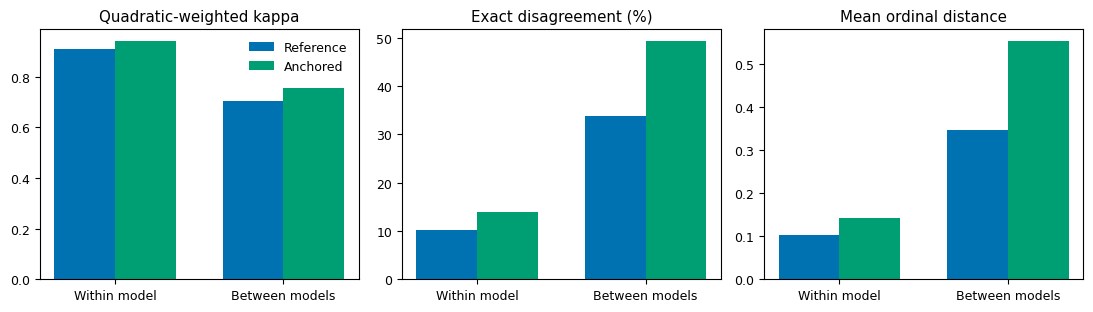

In [12]:
# Notebook-only view of Table A7; no additional inference or metrics.
import matplotlib.pyplot as plt
metrics = [('weighted_kappa', 'Quadratic-weighted kappa', 1),
           ('disagreement_rate', 'Exact disagreement (%)', 100),
           ('ordinal_distance', 'Mean ordinal distance', 1)]
with plt.rc_context({"font.size": 9}):
    fig, axes = plt.subplots(1, 3, figsize=(11, 3.2))
    x = np.arange(2)
    for ax, (metric, title, scale) in zip(axes, metrics):
        for shift, variant, label, color in [(-.18, 'reference', 'Reference', '#0072B2'),
                                             (.18, 'anchored_fewshot', 'Anchored', '#009E73')]:
            values = [agreement.loc[agreement.variant.eq(variant) & agreement.scope.eq(scope) &
                                   agreement.metric.eq(metric), 'estimate'].item() for scope in ['within', 'between']]
            ax.bar(x + shift, scale * np.array(values), width=.36, label=label, color=color)
        ax.set_xticks(x, ['Within model', 'Between models'])
        ax.set_title(title)
        ax.set_ylim(bottom=0)
    axes[0].legend(frameon=False)
    fig.tight_layout()
    display(fig)
    plt.close(fig)


## Order and batch-size effects beyond ordinary reruns

For conditions A and B, cross-setting disagreement uses all nine run combinations;
within-setting disagreement uses the three distinct run pairs. The excess is
`cross − (within_A + within_B) / 2`. This measures a difference between conditional
label distributions rather than treating every independently generated change as
an order effect. The unbiased estimate can be negative with three runs.

Order compares fixed versus reversed 20-item batches on all 1,000 descriptions.
Batch size compares fixed batches versus singleton requests on the same randomly
selected 200 descriptions. A singleton contrast changes neighboring context and
request size together; it cannot separate those mechanisms. Confidence intervals
use the corresponding original blocks, so singleton intervals have only ten
independent resampling blocks and warrant particular caution.

**Reports:** §4.4; Table A9.


In [13]:
context_rows, context_summary_rows = [], []
for variant in PROMPTS:
    for contrast, other_context in [('order', 'batch20_reversed'), ('batch_size', 'single')]:
        mask = sample.single_panel.to_numpy() if contrast == 'batch_size' else np.ones(SAMPLE_N, dtype=bool)
        groups = sample.loc[mask, 'base_batch_id'].to_numpy()
        aggregate = {'modal_disagreement': [], 'cross_disagreement': [], 'excess_disagreement': [], 'excess_ordinal_distance': []}
        for model in MODEL_ORDER:
            a = arrays[(variant, 'batch20_fixed', model)][mask]
            b = arrays[(variant, other_context, model)]
            wa_dist, wa_dis = within_vectors(a); wb_dist, wb_dis = within_vectors(b)
            cross_dist, cross_dis = cross_vectors(a, b)
            values = {'modal_disagreement': (modal_values(a) != modal_values(b)).astype(float),
                      'cross_disagreement': cross_dis,
                      'excess_disagreement': cross_dis - .5 * (wa_dis + wb_dis),
                      'excess_ordinal_distance': cross_dist - .5 * (wa_dist + wb_dist)}
            lo, hi = ci(values['excess_disagreement'], groups)
            context_rows.append({'variant': variant, 'contrast': contrast, 'model': model,
                                  'descriptions': int(mask.sum()), **{k: v.mean() for k, v in values.items()},
                                  'excess_ci_low': lo, 'excess_ci_high': hi,
                                  'within_fixed_disagreement': wa_dis.mean(), 'within_other_disagreement': wb_dis.mean()})
            for key, vector in values.items(): aggregate[key].append(vector)
        averaged = {key: np.mean(values, axis=0) for key, values in aggregate.items()}
        lo, hi = ci(averaged['excess_disagreement'], groups)
        status = 'below illustrative tolerance' if hi < CONTEXT_TOLERANCE else ('exceeds illustrative tolerance' if lo > CONTEXT_TOLERANCE else 'inconclusive at illustrative tolerance')
        context_summary_rows.append({'variant': variant, 'contrast': contrast, 'descriptions': int(mask.sum()),
                                     'bootstrap_blocks': len(np.unique(groups)),
                                     **{k: v.mean() for k, v in averaged.items()},
                                     'excess_ci_low': lo, 'excess_ci_high': hi, 'tolerance': CONTEXT_TOLERANCE,
                                     'tolerance_assessment': status})
context_effects = pd.DataFrame(context_rows)
context_summary = pd.DataFrame(context_summary_rows)
context_effects.to_csv(TABLES / 'context_effects_by_model.csv', index=False)
context_summary.to_csv(TABLES / 'context_effects_summary.csv', index=False)
display(context_summary.round(5))
display(context_effects.round(5))


,variant,contrast,descriptions,bootstrap_blocks,modal_disagreement,cross_disagreement,excess_disagreement,excess_ordinal_distance,excess_ci_low,excess_ci_high,tolerance,tolerance_assessment
0,reference,order,1000,50,0.27233,0.28243,0.18265,0.18846,0.16906,0.19684,0.05,exceeds illustrative tolerance
1,reference,batch_size,200,10,0.41000,0.41065,0.31773,0.33778,0.30000,0.33681,0.05,exceeds illustrative tolerance
2,anchored_fewshot,order,1000,50,0.31950,0.33131,0.19559,0.20928,0.18188,0.20981,0.05,exceeds illustrative tolerance
3,anchored_fewshot,batch_size,200,10,0.36750,0.37444,0.23708,0.28324,0.20903,0.26491,0.05,exceeds illustrative tolerance


,variant,contrast,model,descriptions,modal_disagreement,cross_disagreement,excess_disagreement,excess_ordinal_distance,excess_ci_low,excess_ci_high,within_fixed_disagreement,within_other_disagreement
0,reference,order,GPT-5.6 Sol,1000,0.248,0.25511,0.15561,0.15744,0.12638,0.18772,0.11433,0.08467
1,reference,order,Gemini 3.1 Pro,1000,0.232,0.24000,0.14550,0.14533,0.12188,0.17245,0.09600,0.09300
2,reference,order,Kimi K2.6,1000,0.231,0.26656,0.16222,0.16500,0.13833,0.18856,0.09800,0.11067
3,reference,order,DeepSeek V4 Pro,1000,0.290,0.29689,0.18239,0.19111,0.15443,0.21239,0.12000,0.10900
4,reference,order,Qwen3.5 397B,1000,0.336,0.32878,0.25344,0.26944,0.21833,0.28967,0.06800,0.08267
5,reference,order,GLM-5.2,1000,0.297,0.30722,0.19672,0.20244,0.17005,0.22378,0.11433,0.10667
6,reference,batch_size,GPT-5.6 Sol,200,0.380,0.38167,0.29583,0.29944,0.22917,0.36169,0.08500,0.08667
7,reference,batch_size,Gemini 3.1 Pro,200,0.330,0.32333,0.24667,0.24667,0.18276,0.30500,0.07667,0.07667
8,reference,batch_size,Kimi K2.6,200,0.375,0.38000,0.28500,0.30278,0.22611,0.34168,0.12000,0.07000
9,reference,batch_size,DeepSeek V4 Pro,200,0.400,0.41278,0.27611,0.29889,0.21775,0.33224,0.09667,0.17667


## Predictive performance under each prompt

Every fit uses only sampled training claims, while scoring only sampled claims
from the original validation split. The five few-shot records are outside this
sample, so their observed payments cannot be merged back as target labels. All
models share the same sampled observations, eight peril indicators, Gamma/log-link
response `log1p(Loss)`, and numeric ordinal label specification. We do not tune
prompts or select examples using validation performance.

We report validation log MAE, predictive sum-of-squares R², normalized dollar-loss
Gini and top-decile lift for fixed and reversed batches. For the primary fixed-batch
comparison, paired intervals for the change in log MAE resample original blocks,
retaining claim weights and averaging errors over the three saved runs. The small
holdout and skewed losses limit ranking and performance conclusions; point estimates
are not evidence of operational FNOL or reserving validity.

**Reports:** §4.4; Table A8 (subsample validation, not Table 3).


In [14]:
def concentration_gini(loss, score):
    frame = pd.DataFrame({'loss': np.asarray(loss, float), 'score': np.asarray(score, float)})
    grouped = frame.groupby('score', sort=True).agg(loss=('loss', 'sum'), n=('loss', 'size'))
    x = np.r_[0., grouped.n.cumsum().to_numpy() / len(frame)]
    y = np.r_[0., grouped.loss.cumsum().to_numpy() / frame.loss.sum()]
    return float(1 - 2 * np.trapezoid(y, x))

def ranking_metrics(loss, prediction):
    loss, prediction = np.asarray(loss, float), np.asarray(prediction, float)
    mass = .1 * len(loss)
    cutoff = np.sort(prediction)[::-1][int(np.ceil(mass)) - 1]
    weights = (prediction > cutoff).astype(float)
    ties = prediction == cutoff
    weights[ties] = (mass - weights.sum()) / ties.sum()
    assert np.isclose(weights.sum(), mass)
    return {'normalized_gini': concentration_gini(loss, prediction) / concentration_gini(loss, loss),
            'top_decile_lift': np.dot(weights, loss) / mass / loss.mean()}

train_sample = sample_claims.query("split == 'train'").copy()
valid_sample = sample_claims.query("split == 'validation'").copy()
validation_groups = valid_sample.description_id.map(sample.set_index('description_id').base_batch_id).to_numpy()
assert set(examples.description_id).isdisjoint(train_sample.description_id)
assert set(examples.description_id).isdisjoint(valid_sample.description_id)
performance_rows, coefficient_rows, prediction_rows = [], [], []
errors = {}
def fit_glm(model, variant, context, run, feature=None):
    train = train_sample.copy(); valid = valid_sample.copy()
    cols = PERILS.copy()
    if feature is not None:
        train['label_value'] = train.description_id.map(feature)
        valid['label_value'] = valid.description_id.map(feature)
        assert train.label_value.notna().all() and valid.label_value.notna().all()
        cols.append('label_value')
    xt = sm.add_constant(train[cols].astype(float), has_constant='add')
    xv = sm.add_constant(valid[cols].astype(float), has_constant='add')
    assert np.linalg.matrix_rank(xt) == xt.shape[1], 'Unidentified sample GLM; investigate before reporting.'
    fit = sm.GLM(train.log_loss, xt, family=sm.families.Gamma(link=sm.families.links.Log())).fit(maxiter=1000)
    assert fit.converged
    pred = np.asarray(fit.predict(xv)); y = valid.log_loss.to_numpy()
    assert np.isfinite(pred).all() and (pred > 0).all()
    error = np.abs(y - pred)
    errors[(model, variant, context, run)] = error
    performance_rows.append({'model': model, 'variant': variant, 'context': context, 'run': run,
                              'mae': error.mean(), 'r2': 1 - np.square(y - pred).sum() / np.square(y - y.mean()).sum(),
                              **ranking_metrics(valid.Loss, pred)})
    for term in fit.params.index:
        coefficient_rows.append({'model': model, 'variant': variant, 'context': context, 'run': run,
                                  'term': term, 'estimate': fit.params[term], 'standard_error': fit.bse[term]})
    prediction_rows.extend({'model': model, 'variant': variant, 'context': context, 'run': run, 'claim_row': int(claim_row),
                            'description_id': d, 'observed_loss': float(loss), 'predicted_log_loss': float(p)}
                           for claim_row, d, loss, p in zip(valid.claim_row, valid.description_id, valid.Loss, pred))

fit_glm('No LLM feature', 'baseline', 'baseline', 0)
for variant, context, model, run in product(PROMPTS, ['batch20_fixed', 'batch20_reversed'], MODEL_ORDER, range(1, REPEATS + 1)):
    frame = classifications.query('variant == @variant and context == @context and model == @model and run == @run')
    feature = frame.set_index('description_id').label_value
    fit_glm(model, variant, context, run, feature)
performance = pd.DataFrame(performance_rows)
performance_summary = performance.groupby(['model', 'variant', 'context'], sort=False).agg(
    mean_mae=('mae', 'mean'), sd_mae=('mae', 'std'), mean_r2=('r2', 'mean'),
    mean_gini=('normalized_gini', 'mean'), mean_lift=('top_decile_lift', 'mean')).reset_index()
performance_changes = []
for model in MODEL_ORDER:
    ref = np.mean([errors[(model, 'reference', 'batch20_fixed', r)] for r in range(1, REPEATS + 1)], axis=0)
    imp = np.mean([errors[(model, 'anchored_fewshot', 'batch20_fixed', r)] for r in range(1, REPEATS + 1)], axis=0)
    lo, hi = ci(imp - ref, validation_groups)
    performance_changes.append({'model': model, 'improved_minus_reference_mae': (imp - ref).mean(), 'ci_low': lo, 'ci_high': hi})
performance_change = pd.DataFrame(performance_changes)
sample_baseline_mae = float(performance.query("variant == 'baseline'").mae.iloc[0])
pair_performance_rows = []
for row in between.itertuples(index=False):
    a = performance_summary.query("variant == @row.variant and context == 'batch20_fixed' and model == @row.model_a").iloc[0]
    b = performance_summary.query("variant == @row.variant and context == 'batch20_fixed' and model == @row.model_b").iloc[0]
    difference = abs(a.mean_mae - b.mean_mae)
    pair_performance_rows.append({'variant': row.variant, 'model_a': row.model_a, 'model_b': row.model_b,
                                  'mae_difference': difference, 'mae_difference_pct_baseline': 100 * difference / sample_baseline_mae,
                                  'within_1pct_tolerance': difference < .01 * sample_baseline_mae,
                                  'modal_disagreement': row.modal_disagreement, 'ordinal_distance': row.ordinal_distance})
prompt_pair_performance = pd.DataFrame(pair_performance_rows)
prompt_pair_performance.to_csv(TABLES / 'pairwise_performance_and_disagreement.csv', index=False)
performance.to_csv(TABLES / 'performance_by_run.csv', index=False)
performance_summary.to_csv(TABLES / 'performance_summary.csv', index=False)
performance_change.to_csv(TABLES / 'paired_performance_changes.csv', index=False)
pd.DataFrame(coefficient_rows).to_csv(TABLES / 'glm_coefficients.csv', index=False)
pd.DataFrame(prediction_rows).to_csv(TABLES / 'validation_predictions.csv', index=False)
display(performance_summary.round(5))
display(performance_change.round(5))


,model,variant,context,mean_mae,sd_mae,mean_r2,mean_gini,mean_lift
0,No LLM feature,baseline,baseline,1.22983,NaN,0.25796,0.53095,3.12765
1,GPT-5.6 Sol,reference,batch20_fixed,1.14650,0.00574,0.35292,0.64324,5.08738
2,Gemini 3.1 Pro,reference,batch20_fixed,1.10996,0.00107,0.37355,0.68207,6.16997
3,Kimi K2.6,reference,batch20_fixed,1.15307,0.00673,0.33649,0.59533,3.22913
4,DeepSeek V4 Pro,reference,batch20_fixed,1.17449,0.00465,0.30785,0.59462,3.64554
5,Qwen3.5 397B,reference,batch20_fixed,1.16348,0.00288,0.32607,0.55261,3.60696
6,GLM-5.2,reference,batch20_fixed,1.17489,0.00792,0.32191,0.62969,4.01669
7,GPT-5.6 Sol,reference,batch20_reversed,1.11851,0.00427,0.38289,0.64981,4.08509
8,Gemini 3.1 Pro,reference,batch20_reversed,1.13227,0.00541,0.37669,0.69862,5.55616
9,Kimi K2.6,reference,batch20_reversed,1.14537,0.00281,0.35348,0.62370,4.92266


,model,improved_minus_reference_mae,ci_low,ci_high
0,GPT-5.6 Sol,-0.03805,-0.07916,0.00042
1,Gemini 3.1 Pro,-0.03426,-0.06864,0.00054
2,Kimi K2.6,-0.06098,-0.09836,-0.02418
3,DeepSeek V4 Pro,-0.04529,-0.08097,-0.00714
4,Qwen3.5 397B,-0.02061,-0.04990,0.00767
5,GLM-5.2,-0.04412,-0.07634,-0.01088


## Generate the appendix and brief main-text results

The report is generated only after the complete six-model experiment and all
analyses succeed. It reports the observed sign of each prompt effect, including
increases or inconclusive intervals. The improved prompt changes the task
specification and supplies training supervision; it does not establish a uniquely
correct severity scale or isolate an intrinsic model judgment.

**Reports:** §4.4 and Appendix A.5; only the compact published tables are rendered.


In [15]:
# Tables A7–A9 use the saved analysis CSVs through the shared renderer.
write_primary_appendix(PAPER, 'prompt_analysis')

def metric_row(variant, scope, metric='ordinal_distance'):
    return agreement.query('variant == @variant and scope == @scope and metric == @metric').iloc[0]
mae_improved = int((performance_change.ci_high < 0).sum())
kwr, kwa = metric_row('reference', 'within', 'weighted_kappa'), metric_row('anchored_fewshot', 'within', 'weighted_kappa')
kbr, kba = metric_row('reference', 'between', 'weighted_kappa'), metric_row('anchored_fewshot', 'between', 'weighted_kappa')
# Stop if frozen results no longer support the direction stated in §4.4.
assert performance_change.improved_minus_reference_mae.lt(0).all()
assert kwr.estimate < kwa.estimate and kbr.estimate < kba.estimate
for scope in ['within', 'between']:
    for metric in ['ordinal_distance', 'disagreement_rate']:
        assert metric_row('anchored_fewshot', scope, metric).estimate > metric_row('reference', scope, metric).estimate

text=('% Generated from complete s4_prompt_sensitivity.ipynb results.\n'
      'The training-anchored prompt sensitivity has mixed effects: mean log-MAE improves for all six models '
      f'(paired intervals exclude zero for {mae_improved}), and weighted kappa increases from '
      f'{kwr.estimate:.3f} to {kwa.estimate:.3f} within models and {kbr.estimate:.3f} to {kba.estimate:.3f} '
      'between models. All three measures average the same run-pair comparisons; ordinal distances and '
      'raw disagreement increase with broader category use. '
      'Order and batch-size sensitivity also remain. These results qualify any interpretation of the '
      'original prompt as revealing invariant model judgments; Appendix~\\ref{app:prompt-sensitivity} '
      'reports the core contrasts. Complete prompts and diagnostics remain in the repository supplement.\n')
update_section(PAPER / 'manuscript_body.tex', 'prompt_results', text)
print(text)
print('Updated consolidated prompt sensitivity sections from complete responses.')


% Generated from complete s4_prompt_sensitivity.ipynb results.
The training-anchored prompt sensitivity has mixed effects: mean log-MAE improves for all six models (paired intervals exclude zero for 3), and weighted kappa increases from 0.911 to 0.941 within models and 0.703 to 0.758 between models. All three measures average the same run-pair comparisons; ordinal distances and raw disagreement increase with broader category use. Order and batch-size sensitivity also remain. These results qualify any interpretation of the original prompt as revealing invariant model judgments; Appendix~\ref{app:prompt-sensitivity} reports the core contrasts. Complete prompts and diagnostics remain in the repository supplement.

Updated consolidated prompt sensitivity sections from complete responses.


In [16]:
# Verify leakage controls, design balance, repeat identity, and manuscript artifacts.
assert set(examples.description_id).isdisjoint(sample.description_id)
assert not examples.Description.map(normalize_text).isin(validation.Description.map(normalize_text)).any()
assert np.array_equal(anchor_values, training.Loss.quantile([.2, .4, .6, .8]).to_numpy())
assert len(records) == 10800 and len(classifications) == 79200
assert len(performance) == 73 and len(performance_change) == 6
assert len(within) == 12 and len(between) == 30 and len(context_effects) == 24
assert len(context_summary) == 4
assert np.isfinite(agreement[['estimate', 'ci_low', 'ci_high']]).all().all()
assert np.isfinite(performance[['mae', 'r2', 'normalized_gini', 'top_decile_lift']]).all().all()
for model in MODEL_ORDER:
    for variant in PROMPTS:
        assert arrays[(variant, 'batch20_fixed', model)].shape == (1000, 3)
        assert arrays[(variant, 'batch20_reversed', model)].shape == (1000, 3)
        assert arrays[(variant, 'single', model)].shape == (200, 3)
assert np.isclose(concentration_gini(np.array([1., 2., 4.]), np.ones(3)), 0)
assert np.isclose(ranking_metrics(np.array([1., 2., 4.]), np.array([1., 2., 4.]))['normalized_gini'], 1)
artifact_files = sorted(TABLES.glob('*.csv'))
manifest = pd.DataFrame([{'artifact': str(p.relative_to(ROOT)),
                          'sha256': hashlib.sha256(p.read_bytes()).hexdigest(), 'bytes': p.stat().st_size}
                         for p in artifact_files if p.name != 'artifact_manifest.csv'])
manifest.to_csv(TABLES / 'artifact_manifest.csv', index=False)
display(manifest)
print('Verified complete six-model prompt/context experiment, leakage controls, 73 GLMs, and generated appendix.')


,artifact,sha256,bytes
0,tables/prompt_sensitivity/agreement_by_run_pai...,db556afe9665f2961c4f48de8a1c474e06069fbec6bf11...,24780
1,tables/prompt_sensitivity/agreement_summary.csv,b8be431315a1adde28934e5e762164220fd8b6e208d1af...,1415
2,tables/prompt_sensitivity/between_model.csv,210f69fd75ff2b067266cc735624e9dad18872916e7bac...,4848
3,tables/prompt_sensitivity/category_diversity.csv,90e70783f5593b79bd8f392e2ad8d7057a4bcca9b5ce06...,566
4,tables/prompt_sensitivity/category_use.csv,ceaaf9d3925213a8330c66ca6a290c29be789a1b95de9b...,2409
5,tables/prompt_sensitivity/context_effects_by_m...,dca4940bef9b5969d14afb2af4d923b30ee8daf39cd4c6...,4223
6,tables/prompt_sensitivity/context_effects_summ...,8cecdc9f4cda3588ddf1bd08b901112a35b9426b9b0bfa...,881
7,tables/prompt_sensitivity/fewshot_examples.csv,16a7aeb7957207e22acb120d062dcc0aab320112828cdc...,471
8,tables/prompt_sensitivity/glm_coefficients.csv,f4d1322ce439ca77f0a6fc98cf38180df5c6f8f42c2046...,66878
9,tables/prompt_sensitivity/inference_audit.csv,ac6f6aa3218bb80e58c06d8086158fecd07e4ea9571acc...,721


Verified complete six-model prompt/context experiment, leakage controls, 73 GLMs, and generated appendix.
